# 03 · Evaluate candidates and close the search loop

This notebook maps directly to the supplied diagram:

**Bone datums + patient info → candidate angles → feasibility/support → XGB prediction and EconML contrast → utility → Bayesian optimizer → next candidate.**

The fitted models stay fixed. Only the Gaussian-process search surrogate is updated using candidate utility scores. We return the best **evaluated, supported synthetic candidate**, plus alternatives.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
ARTIFACTS = ROOT / "artifacts" / "notebooks"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})
print("SYNTHETIC ONLY — no clinical conclusions.")

SYNTHETIC ONLY — no clinical conclusions.


In [2]:
from plan_ml_poc.demo import example_patient
from plan_ml_poc.evaluation import PlanEvaluator
from plan_ml_poc.persistence import load_bundle, save_bundle
from plan_ml_poc.schema import PLAN_COLUMNS, REFERENCE
from plan_ml_poc.search import search_plans
from plan_ml_poc.synthetic import make_cases
from plan_ml_poc.training import fit_models, split_cases

model_dir = ARTIFACTS / "models"
if not (model_dir / "models.joblib").exists():
    # Convenience for running this notebook alone; normally notebook 02 fits once.
    train, _ = split_cases(make_cases(3000, SEED), SEED)
    save_bundle(fit_models(train, SEED), model_dir)
bundle = load_bundle(model_dir)  # Only load your own trusted artifacts.
patient = example_patient()
evaluator = PlanEvaluator(bundle, patient)
display(patient)
evaluator.evaluate(np.array([REFERENCE, [1, 0.5, 4], [3, 3, 3]]))

/Users/kevin/kinomatic/plan-ml-poc/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,age,bmi,baseline_function,preop_hka_deg,mldfa_deg,mpta_deg,surgeon_b,hospital_b
0,65,29,50,0,88,88,0,0


,femoral_varus_deg,tibial_varus_deg,tibial_slope_deg,feasible,supported,support_distance,status,synthetic_only,outcome_prediction,effect,ci_lower,ci_upper,anchored_outcome,movement_cost,utility
0,0.0,0.0,3.0,True,True,1.883602,accepted,True,70.524597,0.000000,0.000000,0.000000,70.524597,0.000000,70.524597
1,1.0,0.5,4.0,True,True,1.894313,accepted,True,70.524597,0.292163,0.219519,0.364807,70.816760,0.005513,70.738603
2,3.0,3.0,3.0,False,False,NaN,rejected_constraints,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## The objective and the reference anchor

`anchored_outcome = XGB(patient, reference) + causal_effect(reference → candidate)`

`utility = XGB(patient, reference) + ci_lower(reference → candidate) − movement_cost`

The XGB reference is **constant** for this patient's search, so the ranking depends only on the lower effect bound and the invented movement penalty. We also expose XGB's prediction at each candidate for comparison, but never add it to a full causal benefit and count the effect twice.

The anchored absolute outcome is a hybrid visualization heuristic. An observational reference prediction is not automatically an identified causal baseline. The effect interval is not an interval for the anchored absolute outcome. Lower-bound ranking remains a heuristic; searching many pointwise intervals does not yield selection-adjusted confidence.

A nearest-neighbor check rejects distant combinations of patient, context and treatment. It uses training cases only and a leave-one-out calibration threshold. This is a proximity heuristic, **not a test proving positivity**. Both reference and candidate must pass; no reference support means abstention.

{'stop_reason': 'utility_plateau', 'evaluations': 22, 'rejected_proposals': 1261}


,femoral_varus_deg,tibial_varus_deg,tibial_slope_deg,effect,ci_lower,ci_upper,utility
9,0.308208,0.438157,3.315565,0.396659,0.366382,0.426935,70.889979
8,0.158329,0.667184,3.033946,0.201962,0.166169,0.237756,70.689457
15,0.795822,1.067589,2.812424,0.125984,0.051183,0.200785,70.570783
14,0.997215,0.258296,2.764303,0.099871,0.041703,0.158039,70.563239
0,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,70.524597


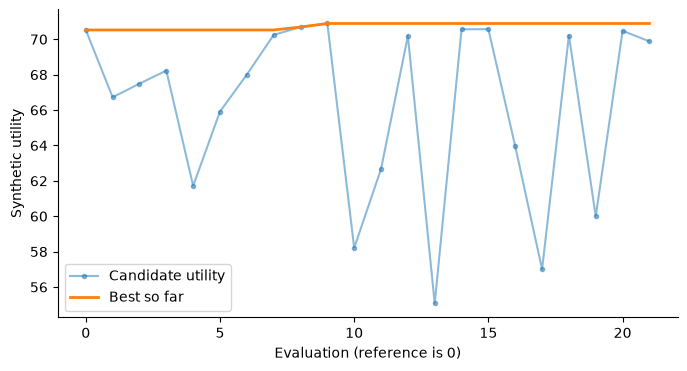

In [3]:
result = search_plans(evaluator, budget=35, startup=7, patience=12, seed=SEED)
print({"stop_reason": result.stop_reason, "evaluations": len(result.history),
       "rejected_proposals": result.rejected_proposals})
display(result.alternatives[PLAN_COLUMNS + ["effect", "ci_lower", "ci_upper", "utility"]])
result.history.to_csv(ARTIFACTS / "bayesian_search.csv", index=False)

plt.plot(result.history.iteration, result.history.utility, ".-", alpha=0.5, label="Candidate utility")
plt.plot(result.history.iteration, result.history.best_so_far, linewidth=2, label="Best so far")
plt.xlabel("Evaluation (reference is 0)")
plt.ylabel("Synthetic utility")
plt.legend()
plt.show()

## What proposes the next plan?

After random startup evaluations, `search.py` fits a Gaussian process to angles → utility. It samples a fresh pool, rejects infeasible/unsupported combinations, computes **Expected Improvement**, then evaluates the largest acquisition value.

**Search GP standard deviation** describes uncertainty about an unevaluated utility value. **EconML's effect interval** describes uncertainty in the estimated conditional contrast. These are different objects.

The loop stops at the evaluation budget, a utility plateau, or failure to find another supported candidate in its finite proposal pool. A plateau is not proof of convergence to a global optimum. Physical mesh construction is not implemented; `feasible()` contains teaching constraints only.

,iteration,phase,acquisition_ei,search_std,effect,ci_lower
10,10,expected_improvement,0.140540,2.532979,-11.837200,-12.270649
11,11,expected_improvement,0.276329,3.626740,-7.352700,-7.802528
12,12,expected_improvement,0.246660,1.775933,-0.210027,-0.324473
13,13,expected_improvement,0.179890,3.583701,-14.913033,-15.405354
14,14,expected_improvement,0.369406,1.044891,0.099871,0.041703
15,15,expected_improvement,0.277938,0.994116,0.125984,0.051183
16,16,expected_improvement,0.252400,3.448549,-6.151677,-6.535086
17,17,expected_improvement,0.215936,3.967509,-12.963994,-13.462250
18,18,expected_improvement,0.283112,1.872749,-0.198695,-0.302783
19,19,expected_improvement,0.257901,4.620244,-10.107352,-10.493456


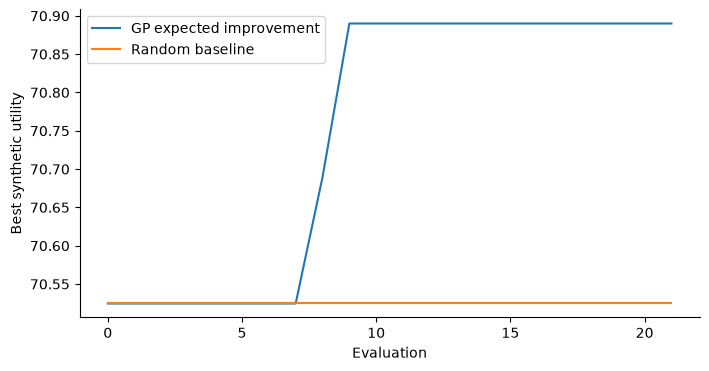

In [4]:
display(result.history[["iteration", "phase", "acquisition_ei", "search_std", "effect", "ci_lower"]].tail(12))
random_result = search_plans(evaluator, budget=len(result.history), seed=SEED,
                             method="random", patience=1000)
plt.plot(result.history.iteration, result.history.best_so_far, label="GP expected improvement")
plt.plot(random_result.history.iteration, random_result.history.best_so_far, label="Random baseline")
plt.xlabel("Evaluation")
plt.ylabel("Best synthetic utility")
plt.legend()
plt.show()

One seed on one patient does not establish that Bayesian optimization wins. This comparison explains the mechanics. Evaluate multiple seeds and fixed independent patients before drawing even simulation-level conclusions.

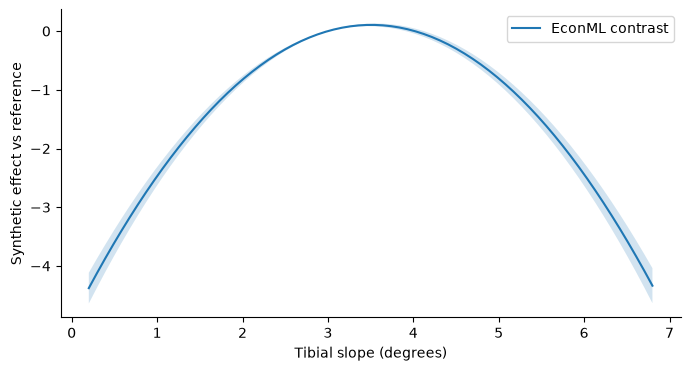

Expected abstention: Unsupported patient/reference; abstaining from plan search.


In [5]:
# Inspect a one-dimensional slice while holding the other angles at reference.
slope = np.linspace(0.2, 6.8, 70)
plans = np.tile(REFERENCE, (len(slope), 1))
plans[:, 2] = slope
curve = evaluator.evaluate(plans)
accepted = curve.status.eq("accepted")
plt.plot(slope[accepted], curve.loc[accepted, "effect"], label="EconML contrast")
plt.fill_between(slope[accepted], curve.loc[accepted, "ci_lower"],
                 curve.loc[accepted, "ci_upper"], alpha=0.2)
plt.xlabel("Tibial slope (degrees)")
plt.ylabel("Synthetic effect vs reference")
plt.legend()
plt.show()

# Out-of-distribution patients should trigger abstention, not an optimistic plan.
extreme = patient.copy()
extreme["age"] = 150
try:
    PlanEvaluator(bundle, extreme)
except ValueError as exc:
    print("Expected abstention:", exc)

**Try next:** change the movement penalty or evaluation budget. Add a new clinical objective only after specifying its units, causal estimand and constraints. To add a fourth angle, update the schema, simulator, treatment model, support model, feasibility rules and notebook contrasts together.